Name : Bhalchim Roshani Ramchandra  
Roll No.: 08  
Title : Interacting with Web APIs  
Problem Statement: Analyzing Weather Data from OpenWeatherMap API  
Dataset: Weather data retrieved from OpenWeatherMap API  
Description: The goal is to interact with the OpenWeatherMap API to retrieve weather data
for a specific location and perform data modeling and visualization to analyze weather
patterns over time.
Tasks to Perform:
1. Register and obtain API key from OpenWeatherMap.
2. Interact with the OpenWeatherMap API using the API key to retrieve weather data for
a specific location.
3. Extract relevant weather attributes such as temperature, humidity, wind speed, and
precipitation from the API response.
4. Clean and preprocess the retrieved data, handling missing values or inconsistent
formats.
5. Perform data modeling to analyze weather patterns, such as calculating average
temperature, maximum/minimum values, or trends over time.
6. Visualize the weather data using appropriate plots, such as line charts, bar plots, or
scatter plots, to represent temperature changes, precipitation levels, or wind speed
variations.
7. Apply data aggregation techniques to summarize weather statistics by specific time
periods (e.g., daily, monthly, seasonal).
8. Incorporate geographical information, if available, to create maps or geospatial
visualizations representing weather patterns across different locations.
9. Explore and visualize relationships between weather attributes, such as temperature
and humidity, using correlation plots or heatmaps.


In [1]:
#!pip install plotly

In [2]:
# Imports
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
# Task 1 and 2: API key and API call for a specific location
API_KEY = "3acd605d0e94309f5e60319b864a1848"   # keep this private, do not upload to GitHub
url = "https://api.openweathermap.org/data/2.5/forecast"
params = {"q": "Pune,IN", "appid": API_KEY, "units": "metric"}

response = requests.get(url, params=params)
print("Status code:", response.status_code)   # 200 means success
data = response.json()
print("City:", data["city"]["name"])
print("Number of records:", len(data["list"]))

Status code: 200
City: Pune
Number of records: 40


In [4]:
# Task 3: Extract temperature, humidity, wind speed and precipitation
rows = []
for item in data["list"]:
    rows.append({
        "datetime": item["dt_txt"],
        "temp": item["main"]["temp"],
        "humidity": item["main"]["humidity"],
        "pressure": item["main"]["pressure"],
        "wind_speed": item["wind"]["speed"],
        "rain_mm": item.get("rain", {}).get("3h"),   # key is missing when it is not raining
        "description": item["weather"][0]["description"]
    })

df = pd.DataFrame(rows)
df.head()

,datetime,temp,humidity,pressure,wind_speed,rain_mm,description
0,2026-10-24 06:00:00,32.46,35,1012,3.54,None,overcast clouds
1,2026-10-24 09:00:00,32.61,33,1011,3.64,None,overcast clouds
2,2026-10-24 12:00:00,29.07,39,1010,0.34,None,overcast clouds
3,2026-10-24 15:00:00,26.35,52,1012,1.59,None,overcast clouds
4,2026-10-24 18:00:00,25.09,55,1012,1.76,None,broken clouds


In [5]:
# Task 4: Clean and preprocess the data
print("Missing values before cleaning:")
print(df.isnull().sum())

df["datetime"] = pd.to_datetime(df["datetime"])
df["rain_mm"] = df["rain_mm"].fillna(0)   # no rain key means 0 mm of rain
df = df.drop_duplicates()

df["date"] = df["datetime"].dt.date
df["hour"] = df["datetime"].dt.hour

print("Missing values after cleaning:", df.isnull().sum().sum())
df.head()

Missing values before cleaning:
datetime        0
temp            0
humidity        0
pressure        0
wind_speed      0
rain_mm        40
description     0
dtype: int64
Missing values after cleaning: 0


,datetime,temp,humidity,pressure,wind_speed,rain_mm,description,date,hour
0,2026-10-24 06:00:00,32.46,35,1012,3.54,0,overcast clouds,2026-10-24,6
1,2026-10-24 09:00:00,32.61,33,1011,3.64,0,overcast clouds,2026-10-24,9
2,2026-10-24 12:00:00,29.07,39,1010,0.34,0,overcast clouds,2026-10-24,12
3,2026-10-24 15:00:00,26.35,52,1012,1.59,0,overcast clouds,2026-10-24,15
4,2026-10-24 18:00:00,25.09,55,1012,1.76,0,broken clouds,2026-10-24,18


In [6]:
# Task 5: Data modeling - average, maximum, minimum and trend
print("Average temperature:", round(df["temp"].mean(), 2))
print("Maximum temperature:", df["temp"].max(), "at", df.loc[df["temp"].idxmax(), "datetime"])
print("Minimum temperature:", df["temp"].min(), "at", df.loc[df["temp"].idxmin(), "datetime"])
print("Average humidity:", round(df["humidity"].mean(), 2))
print("Average wind speed:", round(df["wind_speed"].mean(), 2))
print("Total rainfall:", round(df["rain_mm"].sum(), 2))

# simple linear trend: positive slope means temperature is rising over the period
slope, intercept = np.polyfit(range(len(df)), df["temp"], 1)
print("Temperature trend per 3-hour step:", round(slope, 4))

Average temperature: 26.15
Maximum temperature: 33.1 at 2026-10-25 09:00:00
Minimum temperature: 18.78 at 2026-10-29 00:00:00
Average humidity: 38.28
Average wind speed: 2.42
Total rainfall: 0
Temperature trend per 3-hour step: -0.1534


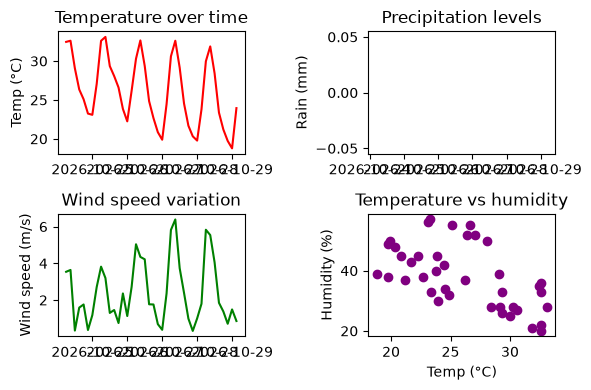

In [8]:
# Task 6: Visualizations (line, bar and scatter)
fig, axes = plt.subplots(2, 2, figsize=(6, 4))

axes[0, 0].plot(df["datetime"], df["temp"], color="red")
axes[0, 0].set_title("Temperature over time")
axes[0, 0].set_ylabel("Temp (°C)")

axes[0, 1].bar(df["datetime"], df["rain_mm"], width=0.1, color="blue")
axes[0, 1].set_title("Precipitation levels")
axes[0, 1].set_ylabel("Rain (mm)")

axes[1, 0].plot(df["datetime"], df["wind_speed"], color="green")
axes[1, 0].set_title("Wind speed variation")
axes[1, 0].set_ylabel("Wind speed (m/s)")

axes[1, 1].scatter(df["temp"], df["humidity"], color="purple")
axes[1, 1].set_title("Temperature vs humidity")
axes[1, 1].set_xlabel("Temp (°C)")
axes[1, 1].set_ylabel("Humidity (%)")

plt.tight_layout()
plt.show()

            avg_temp  max_temp  min_temp  avg_humidity total_rain  avg_wind
date                                                                       
2026-10-24     28.14     32.61     23.25         45.17          0      1.87
2026-10-25     27.96     33.10     23.09         44.38          0      2.10
2026-10-26     26.14     32.65     20.86         34.12          0      2.71
2026-10-27     25.41     32.61     19.89         36.50          0      2.80
2026-10-28     24.77     31.88     19.74         33.88          0      2.77
2026-10-29     21.36     23.95     18.78         34.50          0      1.18


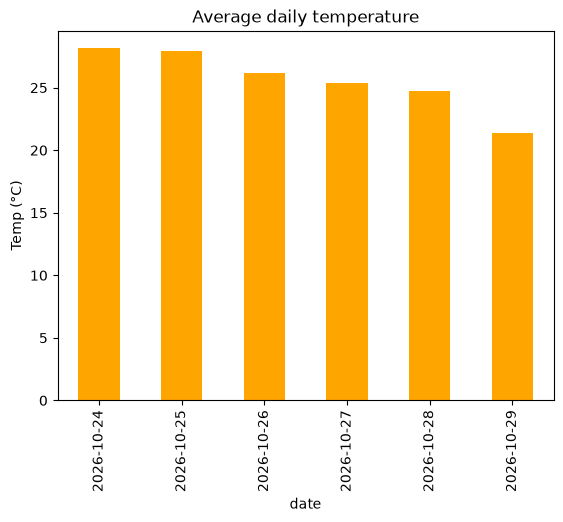

              temp  humidity  wind_speed
part_of_day                             
Afternoon    27.25      35.5        2.27
Evening      22.53      46.1        1.11
Morning      31.88      27.5        4.72
Night        22.92      44.0        1.56


In [9]:
# Task 7: Aggregation by time period (daily summary)
daily = df.groupby("date").agg(
    avg_temp=("temp", "mean"),
    max_temp=("temp", "max"),
    min_temp=("temp", "min"),
    avg_humidity=("humidity", "mean"),
    total_rain=("rain_mm", "sum"),
    avg_wind=("wind_speed", "mean")
).round(2)
print(daily)

daily["avg_temp"].plot(kind="bar", title="Average daily temperature", color="orange")
plt.ylabel("Temp (°C)")
plt.show()

# Aggregation by part of the day
def part_of_day(h):
    if h < 6:
        return "Night"
    elif h < 12:
        return "Morning"
    elif h < 18:
        return "Afternoon"
    else:
        return "Evening"

df["part_of_day"] = df["hour"].apply(part_of_day)
print(df.groupby("part_of_day")[["temp", "humidity", "wind_speed"]].mean().round(2))

In [10]:
# Task 8: Geographical visualization across multiple cities
cities = ["Pune", "Mumbai", "Delhi", "Chennai", "Kolkata", "Bengaluru", "Hyderabad"]
current_url = "https://api.openweathermap.org/data/2.5/weather"

geo_rows = []
for city in cities:
    r = requests.get(current_url, params={"q": city + ",IN", "appid": API_KEY, "units": "metric"}).json()
    geo_rows.append({
        "city": city,
        "lat": r["coord"]["lat"],
        "lon": r["coord"]["lon"],
        "temp": r["main"]["temp"],
        "humidity": r["main"]["humidity"],
        "wind_speed": r["wind"]["speed"]
    })

geo_df = pd.DataFrame(geo_rows)
print(geo_df)

fig = px.scatter_geo(geo_df, lat="lat", lon="lon", color="temp", size="humidity",
                     hover_name="city", scope="asia", color_continuous_scale="RdYlBu_r",
                     title="Current temperature across Indian cities")
fig.update_geos(center={"lat": 22, "lon": 80}, projection_scale=4)
fig.show()

        city      lat      lon   temp  humidity  wind_speed
0       Pune  18.5196  73.8553  30.99        32        3.84
1     Mumbai  19.0144  72.8479  29.71        62        1.32
2      Delhi  28.6667  77.2167  27.50        41        2.04
3    Chennai  13.0878  80.2785  28.12        75        2.02
4    Kolkata  22.5697  88.3697  29.81        53        3.26
5  Bengaluru  12.9762  77.6033  24.55        79        3.71
6  Hyderabad  17.3753  78.4744  30.55        48        4.16
